In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('/content/zomato.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
df.head()

,Unnamed: 0.1,Unnamed: 0,restaurant name,restaurant type,rate (out of 5),num of ratings,avg cost (two people),online_order,table booking,cuisines type,area,local address
0,0,0,#FeelTheROLL,Quick Bites,3.4,7,200.0,No,No,Fast Food,Bellandur,Bellandur
1,1,1,#L-81 Cafe,Quick Bites,3.9,48,400.0,Yes,No,"Fast Food, Beverages","Byresandra,Tavarekere,Madiwala",HSR
2,2,2,#refuel,Cafe,3.7,37,400.0,Yes,No,"Cafe, Beverages",Bannerghatta Road,Bannerghatta Road
3,3,3,'@ Biryani Central,Casual Dining,2.7,135,550.0,Yes,No,"Biryani, Mughlai, Chinese",Marathahalli,Marathahalli
4,4,4,'@ The Bbq,Casual Dining,2.8,40,700.0,Yes,No,"BBQ, Continental, North Indian, Chinese, Bever...",Bellandur,Bellandur


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 7105
Number of columns: 12


In [ ]:
print("Columns in the dataset:")
print(df.columns.tolist())

Columns in the dataset:
['Unnamed: 0.1', 'Unnamed: 0', 'restaurant name', 'restaurant type', 'rate (out of 5)', 'num of ratings', 'avg cost (two people)', 'online_order', 'table booking', 'cuisines type', 'area', 'local address']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7105 entries, 0 to 7104
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0.1           7105 non-null   int64  
 1   Unnamed: 0             7105 non-null   int64  
 2   restaurant name        7105 non-null   object 
 3   restaurant type        7105 non-null   object 
 4   rate (out of 5)        7037 non-null   float64
 5   num of ratings         7105 non-null   int64  
 6   avg cost (two people)  7048 non-null   float64
 7   online_order           7105 non-null   object 
 8   table booking          7105 non-null   object 
 9   cuisines type          7105 non-null   object 
 10  area                   7105 non-null   object 
 11  local address          7105 non-null   object 
dtypes: float64(2), int64(3), object(7)
memory usage: 666.2+ KB


In [ ]:
# Check missing values in each column

print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
Unnamed: 0.1              0
Unnamed: 0                0
restaurant name           0
restaurant type           0
rate (out of 5)          68
num of ratings            0
avg cost (two people)    57
online_order              0
table booking             0
cuisines type             0
area                      0
local address             0
dtype: int64


In [ ]:
# Check for duplicate records

print("Number of duplicate records:")
print(df.duplicated().sum())

Number of duplicate records:
0


In [ ]:
# Statistical summary of numerical columns

df.describe()

,Unnamed: 0.1,Unnamed: 0,rate (out of 5),num of ratings,avg cost (two people)
count,7105.000000,7105.000000,7037.000000,7105.000000,7048.000000
mean,3552.000000,3552.000000,3.514253,188.921042,540.286464
std,2051.181164,2051.181164,0.463249,592.171049,462.902305
min,0.000000,0.000000,1.800000,1.000000,40.000000
25%,1776.000000,1776.000000,3.200000,16.000000,300.000000
50%,3552.000000,3552.000000,3.500000,40.000000,400.000000
75%,5328.000000,5328.000000,3.800000,128.000000,600.000000
max,7104.000000,7104.000000,4.900000,16345.000000,6000.000000


In [ ]:
# Remove unnecessary index columns

df = df.drop(columns=['Unnamed: 0.1', 'Unnamed: 0'])

print("Dataset after removing unnecessary columns:")
print(df.shape)

display(df.head())

Dataset after removing unnecessary columns:
(7105, 10)


,restaurant name,restaurant type,rate (out of 5),num of ratings,avg cost (two people),online_order,table booking,cuisines type,area,local address
0,#FeelTheROLL,Quick Bites,3.4,7,200.0,No,No,Fast Food,Bellandur,Bellandur
1,#L-81 Cafe,Quick Bites,3.9,48,400.0,Yes,No,"Fast Food, Beverages","Byresandra,Tavarekere,Madiwala",HSR
2,#refuel,Cafe,3.7,37,400.0,Yes,No,"Cafe, Beverages",Bannerghatta Road,Bannerghatta Road
3,'@ Biryani Central,Casual Dining,2.7,135,550.0,Yes,No,"Biryani, Mughlai, Chinese",Marathahalli,Marathahalli
4,'@ The Bbq,Casual Dining,2.8,40,700.0,Yes,No,"BBQ, Continental, North Indian, Chinese, Bever...",Bellandur,Bellandur


In [ ]:
# Handle missing values using median

df['rate (out of 5)'] = df['rate (out of 5)'].fillna(
    df['rate (out of 5)'].median()
)

df['avg cost (two people)'] = df['avg cost (two people)'].fillna(
    df['avg cost (two people)'].median()
)

print("Missing values after handling:")
print(df.isnull().sum())

Missing values after handling:
restaurant name          0
restaurant type          0
rate (out of 5)          0
num of ratings           0
avg cost (two people)    0
online_order             0
table booking            0
cuisines type            0
area                     0
local address            0
dtype: int64


In [ ]:
print("Total missing values in dataset:")
print(df.isnull().sum().sum())

Total missing values in dataset:
0


In [ ]:
# Central Tendency

numerical_columns = [
    'rate (out of 5)',
    'num of ratings',
    'avg cost (two people)'
]

print("MEAN:")
print(df[numerical_columns].mean())

print("\nMEDIAN:")
print(df[numerical_columns].median())

print("\nMODE:")
print(df[numerical_columns].mode().iloc[0])

MEAN:
rate (out of 5)            3.514117
num of ratings           188.921042
avg cost (two people)    539.161013
dtype: float64

MEDIAN:
rate (out of 5)            3.5
num of ratings            40.0
avg cost (two people)    400.0
dtype: float64

MODE:
rate (out of 5)            2.8
num of ratings            40.0
avg cost (two people)    300.0
Name: 0, dtype: float64


In [ ]:
# Measures of Dispersion

print("STANDARD DEVIATION:")
print(df[numerical_columns].std())

print("\nVARIANCE:")
print(df[numerical_columns].var())

print("\nRANGE:")
print(df[numerical_columns].max() - df[numerical_columns].min())

print("\nINTERQUARTILE RANGE (IQR):")
print(df[numerical_columns].quantile(0.75) -
      df[numerical_columns].quantile(0.25))

STANDARD DEVIATION:
rate (out of 5)            0.461028
num of ratings           592.171049
avg cost (two people)    461.211329
dtype: float64

VARIANCE:
rate (out of 5)               0.212547
num of ratings           350666.551619
avg cost (two people)    212715.889612
dtype: float64

RANGE:
rate (out of 5)              3.1
num of ratings           16344.0
avg cost (two people)     5960.0
dtype: float64

INTERQUARTILE RANGE (IQR):
rate (out of 5)            0.6
num of ratings           112.0
avg cost (two people)    300.0
dtype: float64


In [ ]:
# Correlation Matrix

correlation_matrix = df[numerical_columns].corr()

print("Correlation Matrix:")
display(correlation_matrix)

Correlation Matrix:


,rate (out of 5),num of ratings,avg cost (two people)
rate (out of 5),1.000000,0.380215,0.374133
num of ratings,0.380215,1.000000,0.340297
avg cost (two people),0.374133,0.340297,1.000000


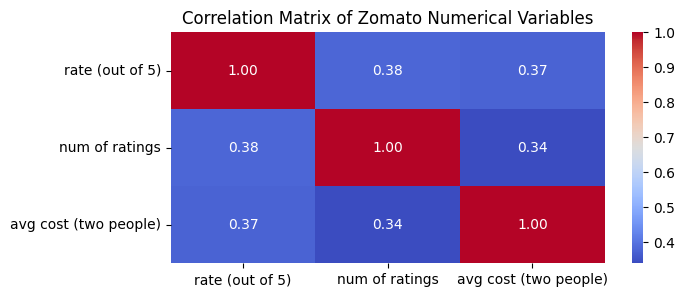

In [ ]:
plt.figure(figsize=(7, 3))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Matrix of Zomato Numerical Variables")
plt.show()

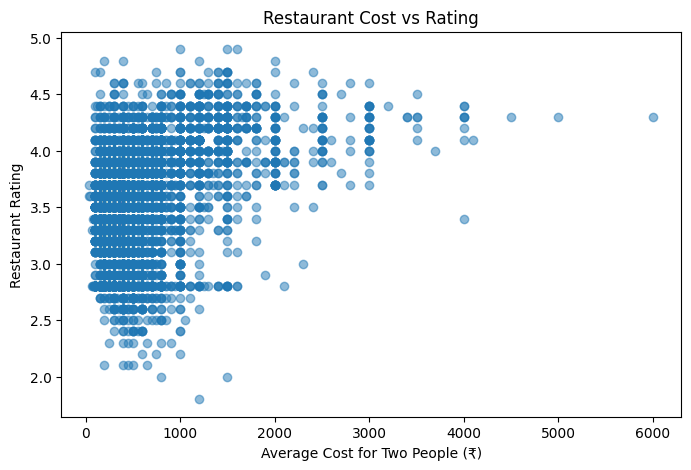

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(
    df['avg cost (two people)'],
    df['rate (out of 5)'],
    alpha=0.5
)
plt.xlabel("Average Cost for Two People (₹)")
plt.ylabel("Restaurant Rating")
plt.title("Restaurant Cost vs Rating")
plt.show()

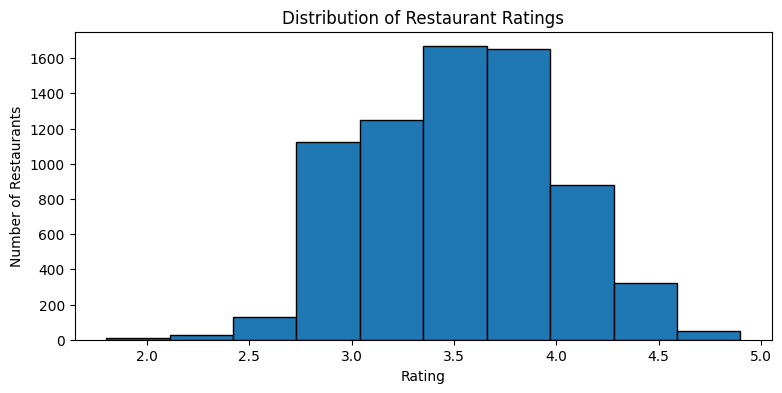

In [ ]:
plt.figure(figsize=(9, 4))

plt.hist(
    df['rate (out of 5)'],
    bins=10,
    edgecolor='black'
)

plt.xlabel("Rating")
plt.ylabel("Number of Restaurants")
plt.title("Distribution of Restaurant Ratings")

plt.show()

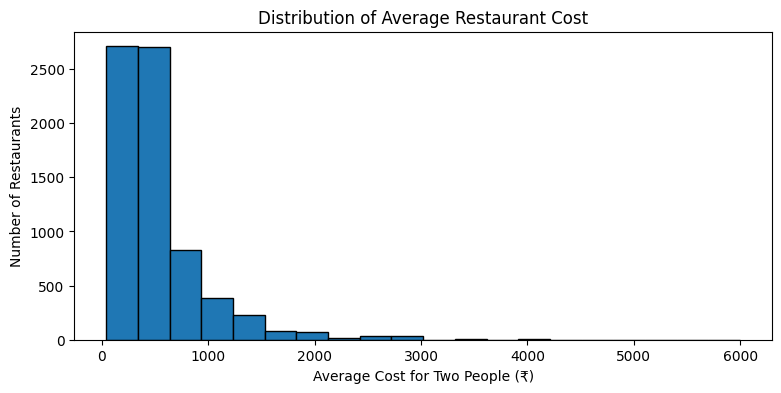

In [ ]:
plt.figure(figsize=(9, 4))

plt.hist(
    df['avg cost (two people)'],
    bins=20,
    edgecolor='black'
)

plt.xlabel("Average Cost for Two People (₹)")
plt.ylabel("Number of Restaurants")
plt.title("Distribution of Average Restaurant Cost")

plt.show()

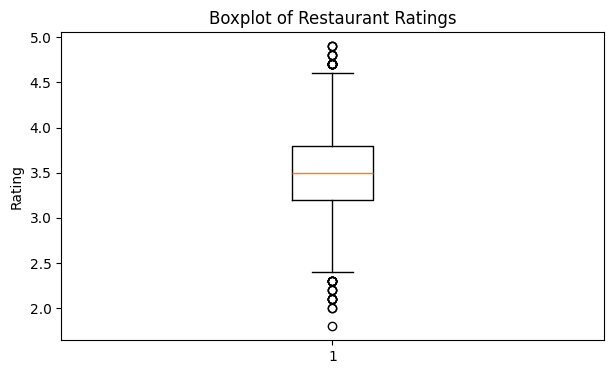

In [ ]:
plt.figure(figsize=(7, 4))

plt.boxplot(df['rate (out of 5)'].dropna())

plt.ylabel("Rating")
plt.title("Boxplot of Restaurant Ratings")

plt.show()

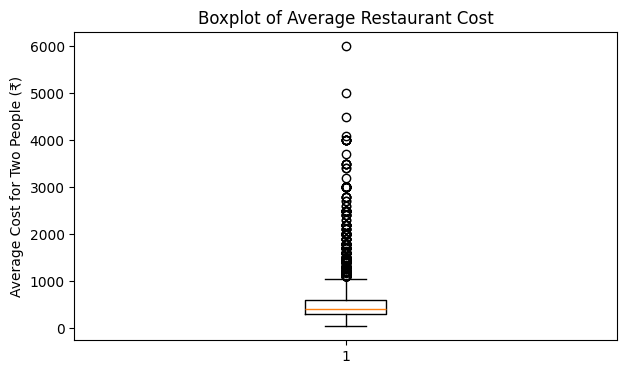

In [ ]:
plt.figure(figsize=(7, 4))

plt.boxplot(df['avg cost (two people)'].dropna())

plt.ylabel("Average Cost for Two People (₹)")
plt.title("Boxplot of Average Restaurant Cost")

plt.show()

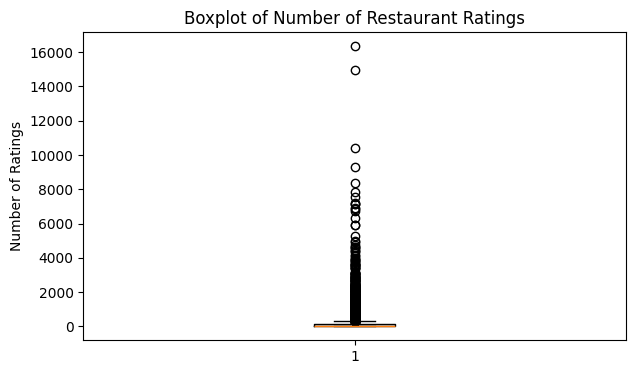

In [ ]:
plt.figure(figsize=(7, 4))

plt.boxplot(df['num of ratings'])

plt.ylabel("Number of Ratings")
plt.title("Boxplot of Number of Restaurant Ratings")

plt.show()

In [ ]:
restaurant_type_counts = df['restaurant type'].value_counts()

print("Restaurant Type Distribution:")
display(restaurant_type_counts)

Restaurant Type Distribution:


,count
restaurant type,
Quick Bites,2840
Casual Dining,1634
Cafe,403
Delivery,358
"Takeaway, Delivery",289
...,...
"Food Court, Beverage Shop",1
"Quick Bites, Food Court",1
"Casual Dining, Sweet Shop",1


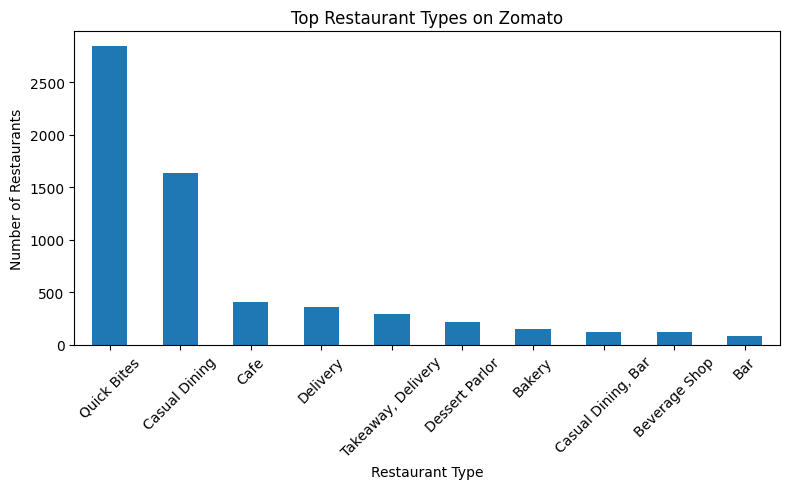

In [ ]:
plt.figure(figsize=(8, 5))

restaurant_type_counts.head(10).plot(kind='bar')

plt.xlabel("Restaurant Type")
plt.ylabel("Number of Restaurants")
plt.title("Top Restaurant Types on Zomato")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [ ]:
online_order_counts = df['online_order'].value_counts()

print(online_order_counts)


online_order
Yes    3727
No     3378
Name: count, dtype: int64


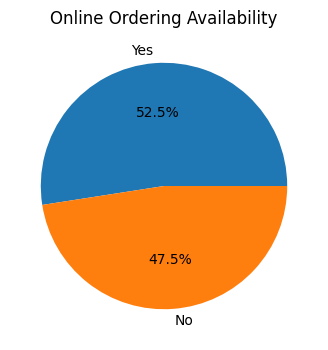

In [ ]:
plt.figure(figsize=(6, 4))

online_order_counts.plot(
    kind='pie',
    autopct='%1.1f%%'
)

plt.ylabel("")
plt.title("Online Ordering Availability")

plt.show()

In [ ]:
table_booking_counts = df['table booking'].value_counts()

print(table_booking_counts)

table booking
No     6361
Yes     744
Name: count, dtype: int64


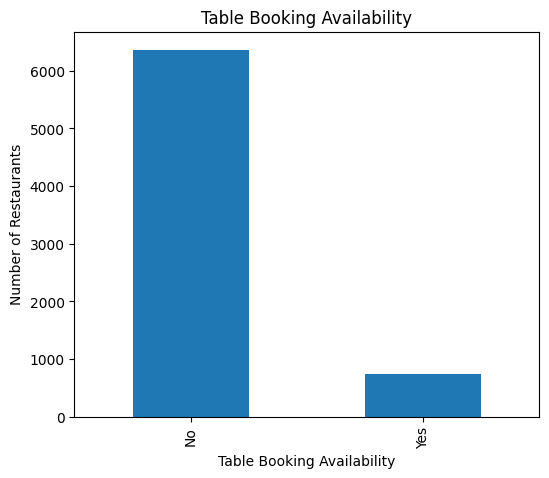

In [ ]:
plt.figure(figsize=(6, 5))

table_booking_counts.plot(
    kind='bar'
)

plt.xlabel("Table Booking Availability")
plt.ylabel("Number of Restaurants")
plt.title("Table Booking Availability")

plt.show()

In [ ]:
cuisine_counts = df['cuisines type'].value_counts()

print("Top 10 Cuisines:")
display(cuisine_counts.head(10))

Top 10 Cuisines:


,count
cuisines type,
"North Indian, Chinese",421
North Indian,420
South Indian,348
Fast Food,140
"South Indian, North Indian, Chinese",128
Biryani,122
"Bakery, Desserts",97
Desserts,87
Cafe,85


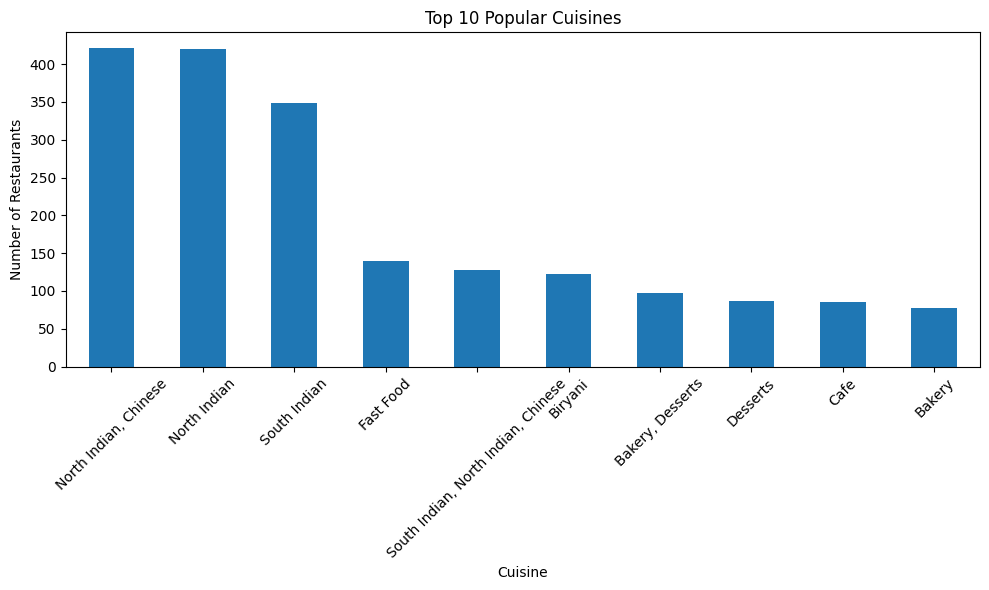

In [ ]:
plt.figure(figsize=(10, 6))

cuisine_counts.head(10).plot(kind='bar')

plt.xlabel("Cuisine")
plt.ylabel("Number of Restaurants")
plt.title("Top 10 Popular Cuisines")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [ ]:
top_rated = df[df['num of ratings'] >= 100].sort_values(
    by='rate (out of 5)',
    ascending=False
)

print("Top Rated Restaurants with at least 100 ratings:")
display(
    top_rated[
        ['restaurant name',
         'restaurant type',
         'rate (out of 5)',
         'num of ratings',
         'avg cost (two people)',
         'area']
    ].head(10)
)

Top Rated Restaurants with at least 100 ratings:


,restaurant name,restaurant type,rate (out of 5),num of ratings,avg cost (two people),area
466,Asia Kitchen By Mainland China,"Casual Dining, Bar",4.9,2178,1500.0,"Byresandra,Tavarekere,Madiwala"
1035,Byg Brewski Brewing Company,Microbrewery,4.9,16345,1600.0,Bellandur
5271,SantÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃÂÃ...,Casual Dining,4.9,246,1000.0,Old Airport Road
4444,O.G. Variar & Sons,Bakery,4.8,1156,200.0,Malleshwaram
6496,The Pizza Bakery,Casual Dining,4.8,1724,1200.0,Indiranagar
668,Belgian Waffle Factory,Dessert Parlor,4.8,186,400.0,"Byresandra,Tavarekere,Madiwala"
4827,Punjab Grill,Casual Dining,4.8,650,2000.0,Whitefield
6242,The Black Pearl,"Casual Dining, Bar",4.7,10413,1400.0,"Byresandra,Tavarekere,Madiwala"
2149,Flechazo,Casual Dining,4.7,7154,1400.0,Marathahalli
7040,You Mee,Casual Dining,4.7,231,2000.0,Brookefield


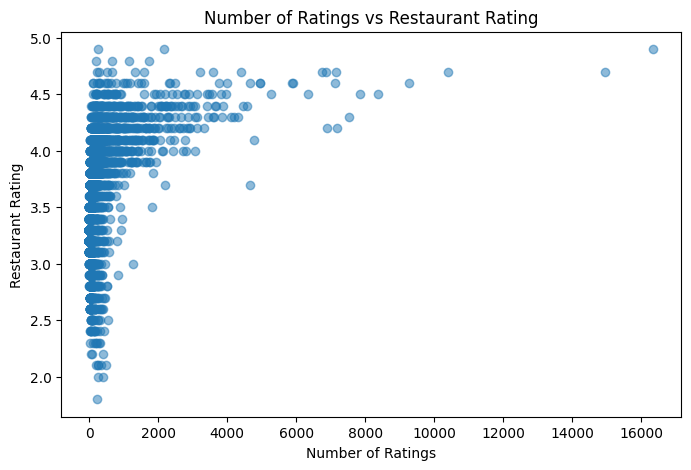

In [ ]:
# Scatter Plot: Number of Ratings vs Rating
plt.figure(figsize=(8, 5))
plt.scatter(
    df['num of ratings'],
    df['rate (out of 5)'],
    alpha=0.5
)
plt.xlabel("Number of Ratings")
plt.ylabel("Restaurant Rating")
plt.title("Number of Ratings vs Restaurant Rating")
plt.show()